In [2]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.markers as mmarkers
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
SUBJECTSUBJECT_CORRELATIONS_CSV_PATH = f'{RESULTS_DIR}/subjectsubject_correlations_nsd515.csv'


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Font name from TTC: Avenir
Style: Book


# Intact vs. t-value=7 (Optimized alpha)

## Median

In [ ]:
savefig = True

ridge_alphaopt_lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_roioptimizedalpha.csv'
lesion_csv = pd.read_csv(ridge_alphaopt_lesion_csv_path)
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

plot_dir = f'{PLOTS_DIR}/fig5/intact_t7_lesioned'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
mappers = ['ridge', 'l1positive']
subjects = [1, 2, 5, 7]
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, fmri_froi
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_normed_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'layer_normed_rdmr': 'median',
	'lesion_raw_pearsonr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()
# Take median across frois for each model
results_df_froimedian = results_df_froi_sbjmedian.groupby(
    ['model']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_normed_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'layer_normed_rdmr': 'median',
	'lesion_raw_pearsonr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3]
# fig, axs = plt.subplots(len(metrics), len(mappers), figsize=(5*len(mappers), 5*len(metrics)), dpi=300)

for mpidx, mapper in enumerate(mappers):
    fig, axs = plt.subplots(len(metrics), 1, figsize=(5*1, 5*len(metrics)), dpi=300)
    for midx, metric in enumerate(metrics):
        if mapper == 'l1positive':
            print('L1-positive not implemented yet, making a mockup')
            froi_pts = lesion_pts = np.array([])
        else:
            froi_pts = np.array(results_df_froimedian[f'layer_{metric}'].tolist())
            lesion_pts = np.array(results_df_froimedian[f'lesion_{metric}'].tolist())
        x_froi = (np.ones(len(froi_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        axs[midx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx].plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(froi_pts), np.median(lesion_pts)]
        sems = [froi_pts.std() / np.sqrt(len(froi_pts)), lesion_pts.std() / np.sqrt(len(lesion_pts))]

        axs[midx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
        # plt.text(0.95, 0.89,
        #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
        #          horizontalalignment='right', verticalalignment='bottom',
        #          transform=plt.gca().transAxes)
        print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")

        axs[midx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx].spines['top'].set_visible(False)
        axs[midx].spines['right'].set_visible(False)
        axs[midx].spines['left'].set_position(('outward', 5))
        axs[midx].spines['bottom'].set_position(('outward', 5))
        axs[midx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx].spines['bottom'].set_bounds(x[0], x[1])
        axs[midx].set_xticks(x, ['Intact', 'Lesioned'])
        axs[midx].set_xlim(x[0]-0.25, x[1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)

        # if froi != 'FFA':
        #     plt.gca().spines['left'].set_visible(False)
        #     # Stop showing y-axis ticks
        #     plt.gca().yaxis.set_ticks([])

    plt.tight_layout()
    if savefig:
        plt.savefig(f'{plot_dir}/lesioned_{mapper}_medianfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
    else:
        plt.show()
    plt.close()

t-value: 0.42
p-value: 6.76e-01
t-value: 0.33
p-value: 7.45e-01
L1-positive not implemented yet, making a mockup
t-value: nan
p-value: nan
L1-positive not implemented yet, making a mockup
t-value: nan
p-value: nan


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/numpy/_core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/om2/user/alishd/ana

## Individual fROIs (Ridge): Old (Layer vs. Lesion)

### Stats

In [2]:
ridge_froi_lesion_stats = []

ridge_alphaopt_lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_roioptimizedalpha.csv'
lesion_csv = pd.read_csv(ridge_alphaopt_lesion_csv_path)
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

# Load fixed alpha results to get the % of units lesioned
lesion_fixedalpha_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_fixedalpha_csv = pd.read_csv(lesion_fixedalpha_csv_path)

results_df = lesion_csv.copy()
frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7
subjects = [1, 2, 5, 7]
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_normed_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'layer_normed_rdmr': 'median',
	'lesion_raw_pearsonr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        froi_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        # Test normality of the data
        froi_norm_pvalue = scipy.stats.shapiro(froi_pts)[1]
        lesion_norm_pvalue = scipy.stats.shapiro(lesion_pts)[1]

        # Conduct Welch's t-test, one-sided two-sample t-test
        welch_tstat, welch_pvalue = scipy.stats.ttest_ind(
            froi_pts, lesion_pts, equal_var=False, alternative='greater'
        )
        
        
        # Conduct Mann-Whitney U test, one-sided two-sample test
        mw_ustat, mw_pvalue = scipy.stats.mannwhitneyu(
            froi_pts, lesion_pts, alternative='greater', use_continuity=True,
            nan_policy='omit'
        )

        # Append to stats list
        ridge_froi_lesion_stats.append({
            'froi': froi,
            'metric': metric,
            'froi_normality_pvalue': froi_norm_pvalue,
            'lesion_normality_pvalue': lesion_norm_pvalue,
            'welch_tstat': welch_tstat,
            'welch_pvalue': welch_pvalue,
            'mw_ustat': mw_ustat,
            'mw_pvalue': mw_pvalue,
        })

# Convert to dataframe
ridge_froi_lesion_stats_df = pd.DataFrame(ridge_froi_lesion_stats)
# Sort according to froi and metric
ridge_froi_lesion_stats_df = ridge_froi_lesion_stats_df.sort_values(by=['froi', 'metric'])
# Display
display(ridge_froi_lesion_stats_df)

# ridge_froi_lesion_stats_df.to_csv(f'{RESULTS_DIR}/ridge_froi_lesion_stats.csv', index=False)

,froi,metric,froi_normality_pvalue,lesion_normality_pvalue,welch_tstat,welch_pvalue,mw_ustat,mw_pvalue
4,EBA,normed_pearsonr,0.110262,0.138103,0.109862,0.456421,631.0,0.416276
5,EBA,normed_rdmr,0.064255,0.113575,0.146626,0.441931,640.0,0.375567
0,FFA,normed_pearsonr,0.000929,0.000733,0.668334,0.253092,698.0,0.159038
1,FFA,normed_rdmr,0.007576,0.004736,0.780479,0.218909,705.0,0.139929
2,PPA,normed_pearsonr,0.232351,0.199302,0.096236,0.461808,633.0,0.407135
3,PPA,normed_rdmr,0.255290,0.213660,0.104418,0.458572,632.0,0.411699


### Plot

In [3]:
savefig = True

ridge_alphaopt_lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_roioptimizedalpha.csv'
lesion_csv = pd.read_csv(ridge_alphaopt_lesion_csv_path)
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

# Load fixed alpha results to get the % of units lesioned
lesion_fixedalpha_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_fixedalpha_csv = pd.read_csv(lesion_fixedalpha_csv_path)

plot_dir = f'{PLOTS_DIR}/fig5/intact_t7_lesioned'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7
subjects = [1, 2, 5, 7]
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_normed_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'layer_normed_rdmr': 'median',
	'lesion_raw_pearsonr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        froi_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        x_froi = (np.ones(len(froi_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx, fidx].plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(froi_pts), np.median(lesion_pts)]
        sems = [froi_pts.std() / np.sqrt(len(froi_pts)), lesion_pts.std() / np.sqrt(len(lesion_pts))]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
        print(f"froi: {froi}, metric: {metric}: t-value: {t_value:.2f}, p-value: {p_value:.2e}")

        # Get % units lesioned for this froi
        # For specific froi & fmri_tthreshold, get results_df
        lesion_fixedalpha_csv_froi = lesion_fixedalpha_csv[
            (lesion_fixedalpha_csv['model_froi'] == froi) &
            (lesion_fixedalpha_csv['fmri_froi'] == froi) &
            (lesion_fixedalpha_csv['model_tthreshold'] == t_threshold) &
            (lesion_fixedalpha_csv['fmri_tthreshold'] == t_threshold)
        ]
        # Take median across subjects for each model, model_threshold
        lesion_fixedalpha_csv_froi_sbjmedian = lesion_fixedalpha_csv_froi.groupby(
            ['model', 'model_tthreshold']
        ).agg({
            'percent_units_lesioned': 'mean',
        }).reset_index()
        percent_lesioned_list = lesion_fixedalpha_csv_froi_sbjmedian['percent_units_lesioned']
        pl_mean = np.mean(percent_lesioned_list)
        pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        axs[midx, fidx].text(
                x[-1], 0.95,
                f"{pl_mean:.1f} ± {pl_sem:.1f}%",
                horizontalalignment='center', verticalalignment='bottom',
                fontsize=12, color='black', alpha=0.8
            )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[1])
        axs[midx, fidx].set_xticks(x, ['All Units', 'All Units except fROI'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model training features', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig5_allunitsEM_froilesionedEM.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

froi: FFA, metric: normed_pearsonr: t-value: 0.67, p-value: 5.06e-01
froi: FFA, metric: normed_rdmr: t-value: 0.78, p-value: 4.38e-01
froi: PPA, metric: normed_pearsonr: t-value: 0.10, p-value: 9.24e-01
froi: PPA, metric: normed_rdmr: t-value: 0.10, p-value: 9.17e-01
froi: EBA, metric: normed_pearsonr: t-value: 0.11, p-value: 9.13e-01
froi: EBA, metric: normed_rdmr: t-value: 0.15, p-value: 8.84e-01


### Check Ceiling

/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/om2/user/alishd/anaconda/envs/catsel/lib/pyth

froi: FFA, metric: normed_pearsonr: t-value: -1.33, p-value: 1.94e-01
froi: FFA, metric: normed_rdmr: t-value: -6.62, p-value: 1.38e-07
froi: PPA, metric: normed_pearsonr: t-value: -9.65, p-value: 2.87e-11
froi: PPA, metric: normed_rdmr: t-value: -12.86, p-value: 1.31e-14
froi: EBA, metric: normed_pearsonr: t-value: -2.80, p-value: 8.47e-03
froi: EBA, metric: normed_rdmr: t-value: -3.92, p-value: 4.08e-04


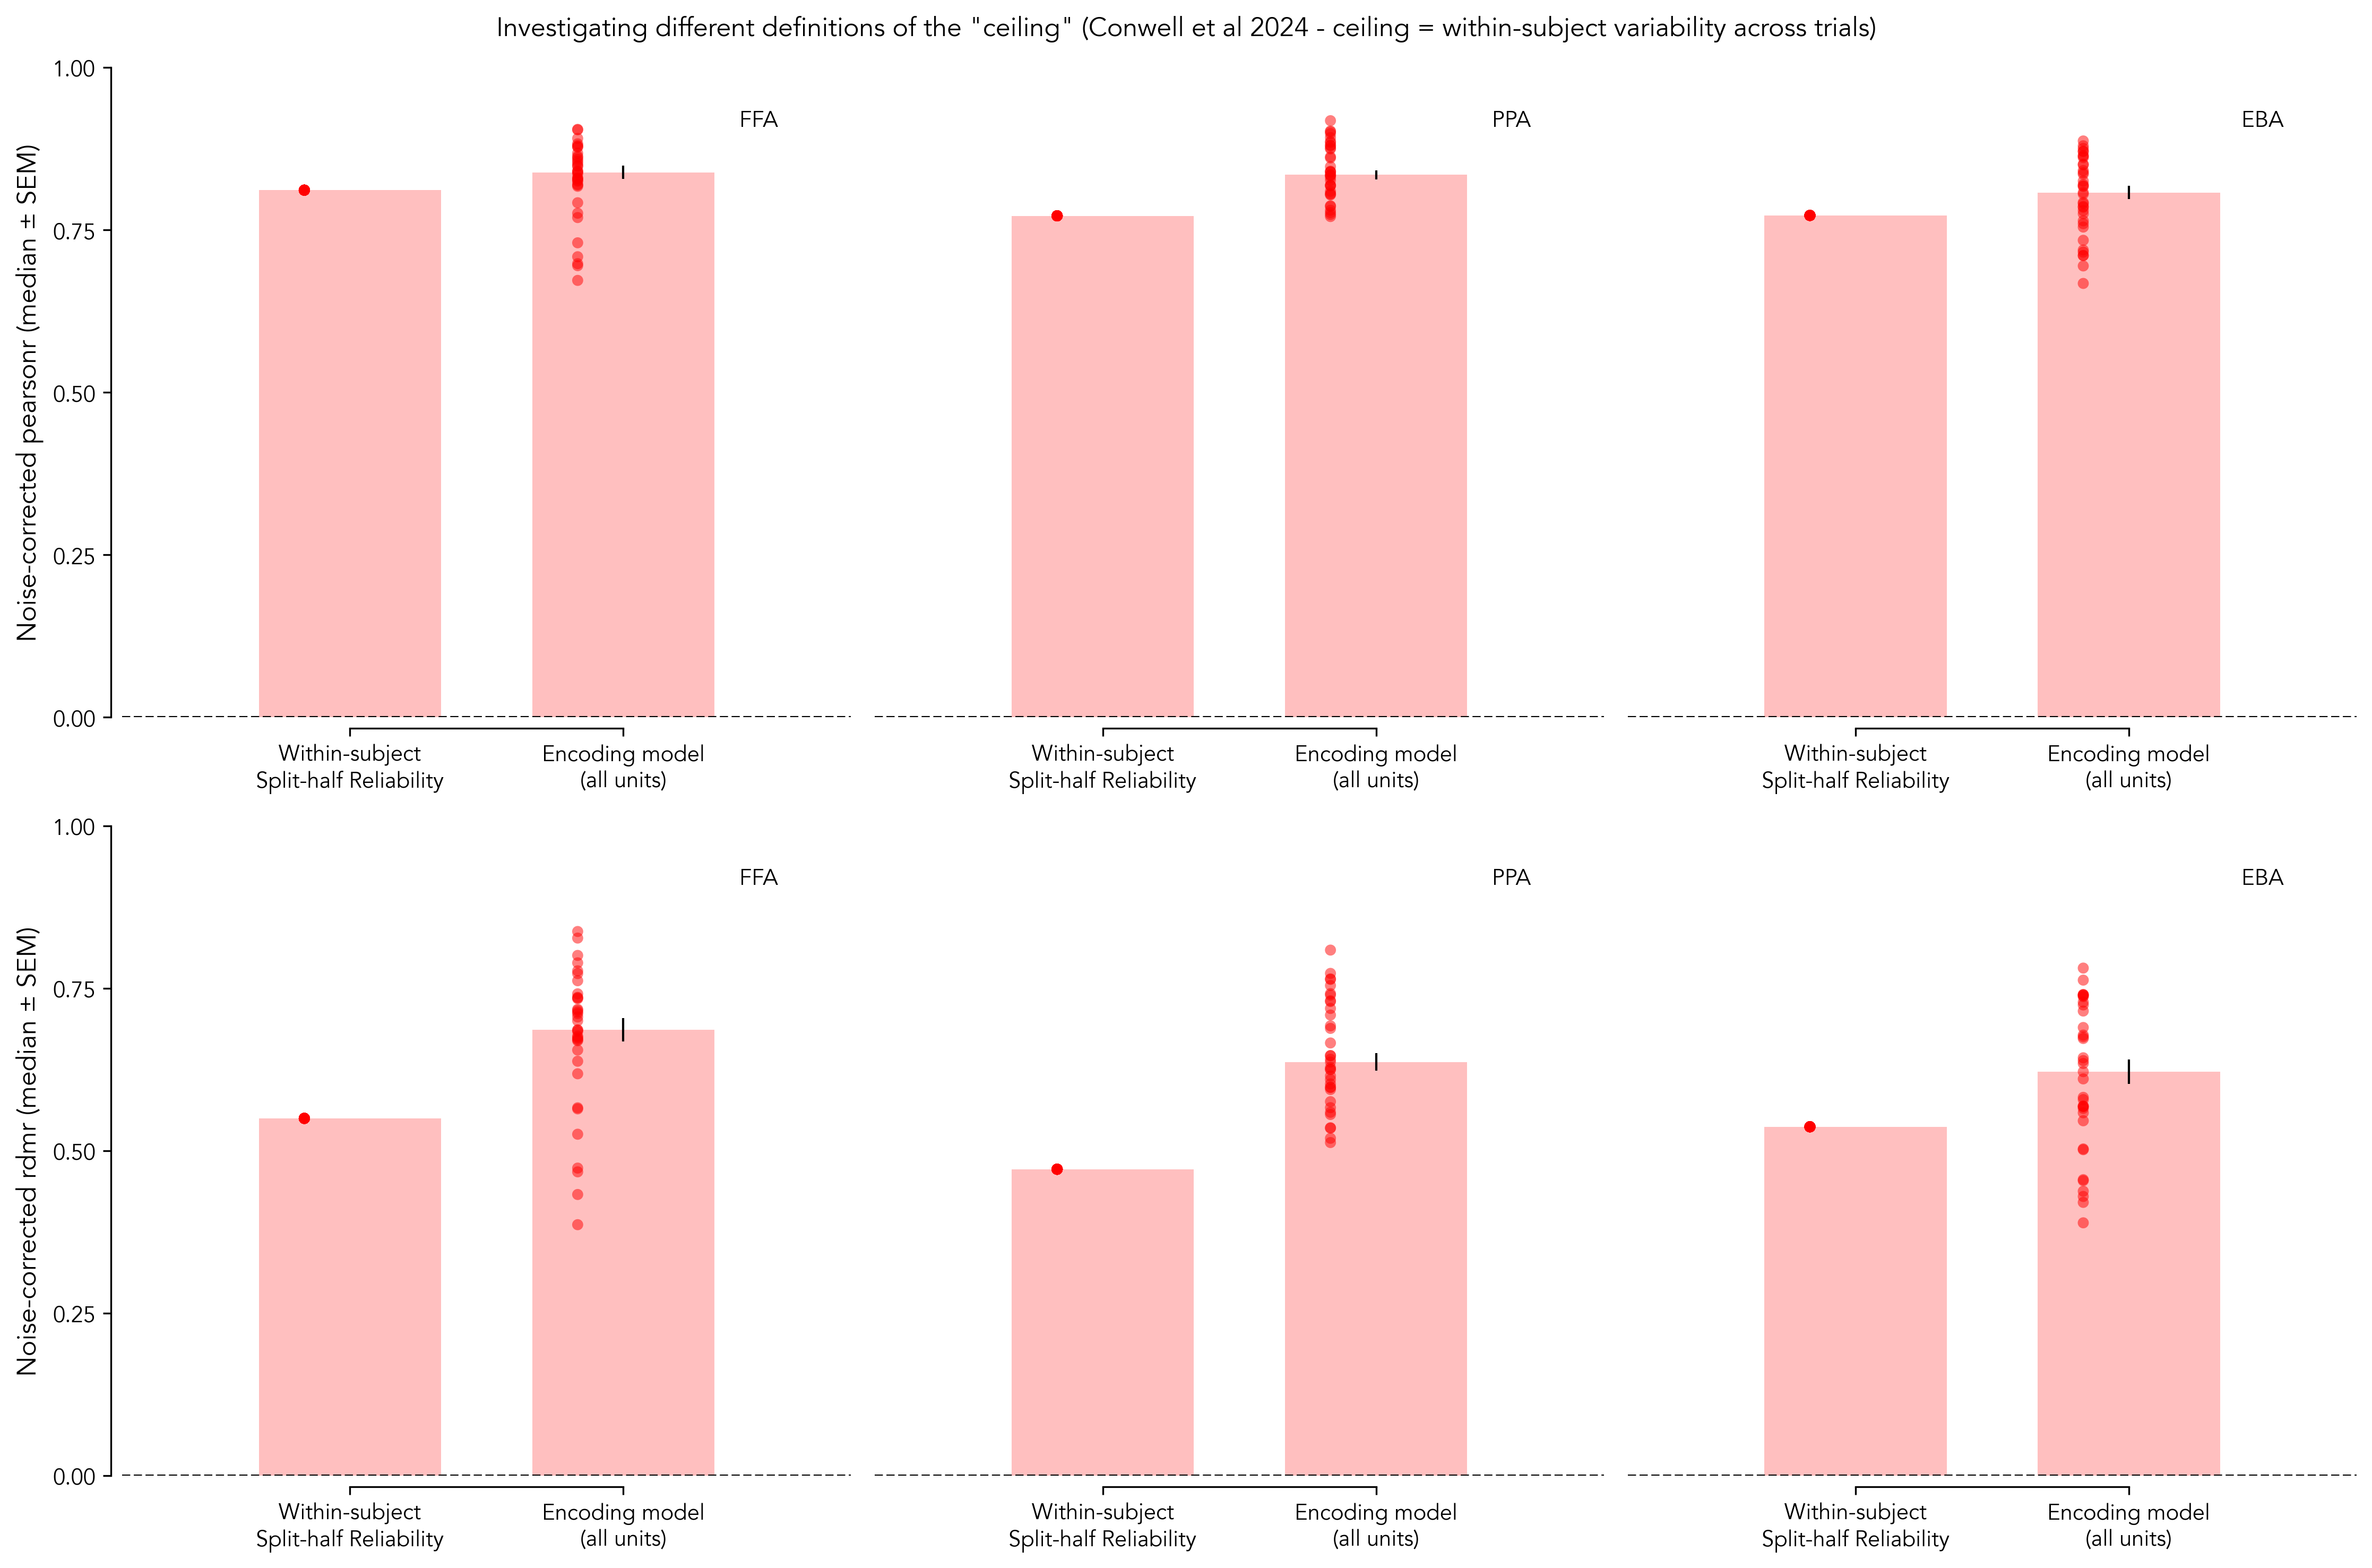

In [ ]:
savefig = False

ridge_alphaopt_lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_ridge_roioptimizedalpha.csv'
lesion_csv = pd.read_csv(ridge_alphaopt_lesion_csv_path)
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)

# Load fixed alpha results to get the % of units lesioned
lesion_fixedalpha_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_fixedalpha_csv = pd.read_csv(lesion_fixedalpha_csv_path)

plot_dir = f'{PLOTS_DIR}/fig5/intact_t7_lesioned'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7
subjects = [1, 2, 5, 7]
metrics = ['normed_pearsonr', 'normed_rdmr']

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
    'layer_raw_pearsonr': 'median',
    'layer_normed_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
    'layer_normed_rdmr': 'median',
	'lesion_raw_pearsonr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        celing_col_name = f'fmri_splithalf_{metric.split("_")[-1]}'
        froi_pts = np.array(results_df_froi[celing_col_name].tolist())
        lesion_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())

        x_froi = (np.ones(len(froi_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        # for i in range(len(froi_pts)):
        #     axs[midx, fidx].plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(froi_pts), np.median(lesion_pts)]
        sems = [froi_pts.std() / np.sqrt(len(froi_pts)), lesion_pts.std() / np.sqrt(len(lesion_pts))]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Conduct Welch's t-test
        t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
        print(f"froi: {froi}, metric: {metric}: t-value: {t_value:.2f}, p-value: {p_value:.2e}")

        # Get % units lesioned for this froi
        # For specific froi & fmri_tthreshold, get results_df
        lesion_fixedalpha_csv_froi = lesion_fixedalpha_csv[
            (lesion_fixedalpha_csv['model_froi'] == froi) &
            (lesion_fixedalpha_csv['fmri_froi'] == froi) &
            (lesion_fixedalpha_csv['model_tthreshold'] == t_threshold) &
            (lesion_fixedalpha_csv['fmri_tthreshold'] == t_threshold)
        ]
        # Take median across subjects for each model, model_threshold
        lesion_fixedalpha_csv_froi_sbjmedian = lesion_fixedalpha_csv_froi.groupby(
            ['model', 'model_tthreshold']
        ).agg({
            'percent_units_lesioned': 'mean',
        }).reset_index()
        percent_lesioned_list = lesion_fixedalpha_csv_froi_sbjmedian['percent_units_lesioned']
        pl_mean = np.mean(percent_lesioned_list)
        pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        # axs[midx, fidx].text(
        #         x[-1], 0.95,
        #         f"{pl_mean:.1f} ± {pl_sem:.1f}%",
        #         horizontalalignment='center', verticalalignment='bottom',
        #         fontsize=12, color='black', alpha=0.8
        #     )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[1])
        axs[midx, fidx].set_xticks(x, ['Within-subject\nSplit-half Reliability', 'Encoding model\n(all units)'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.suptitle('Investigating different definitions of the \"ceiling\" (Conwell et al 2024 ceiling = within-subject variability across trials)')

plt.tight_layout()
if savefig:
    raise NotImplementedError("Exploration only")
    plt.savefig(f'{plot_dir}/lesioned_ridge_individualfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

## Individual fROIs (Ridge) (Fixed alpha)

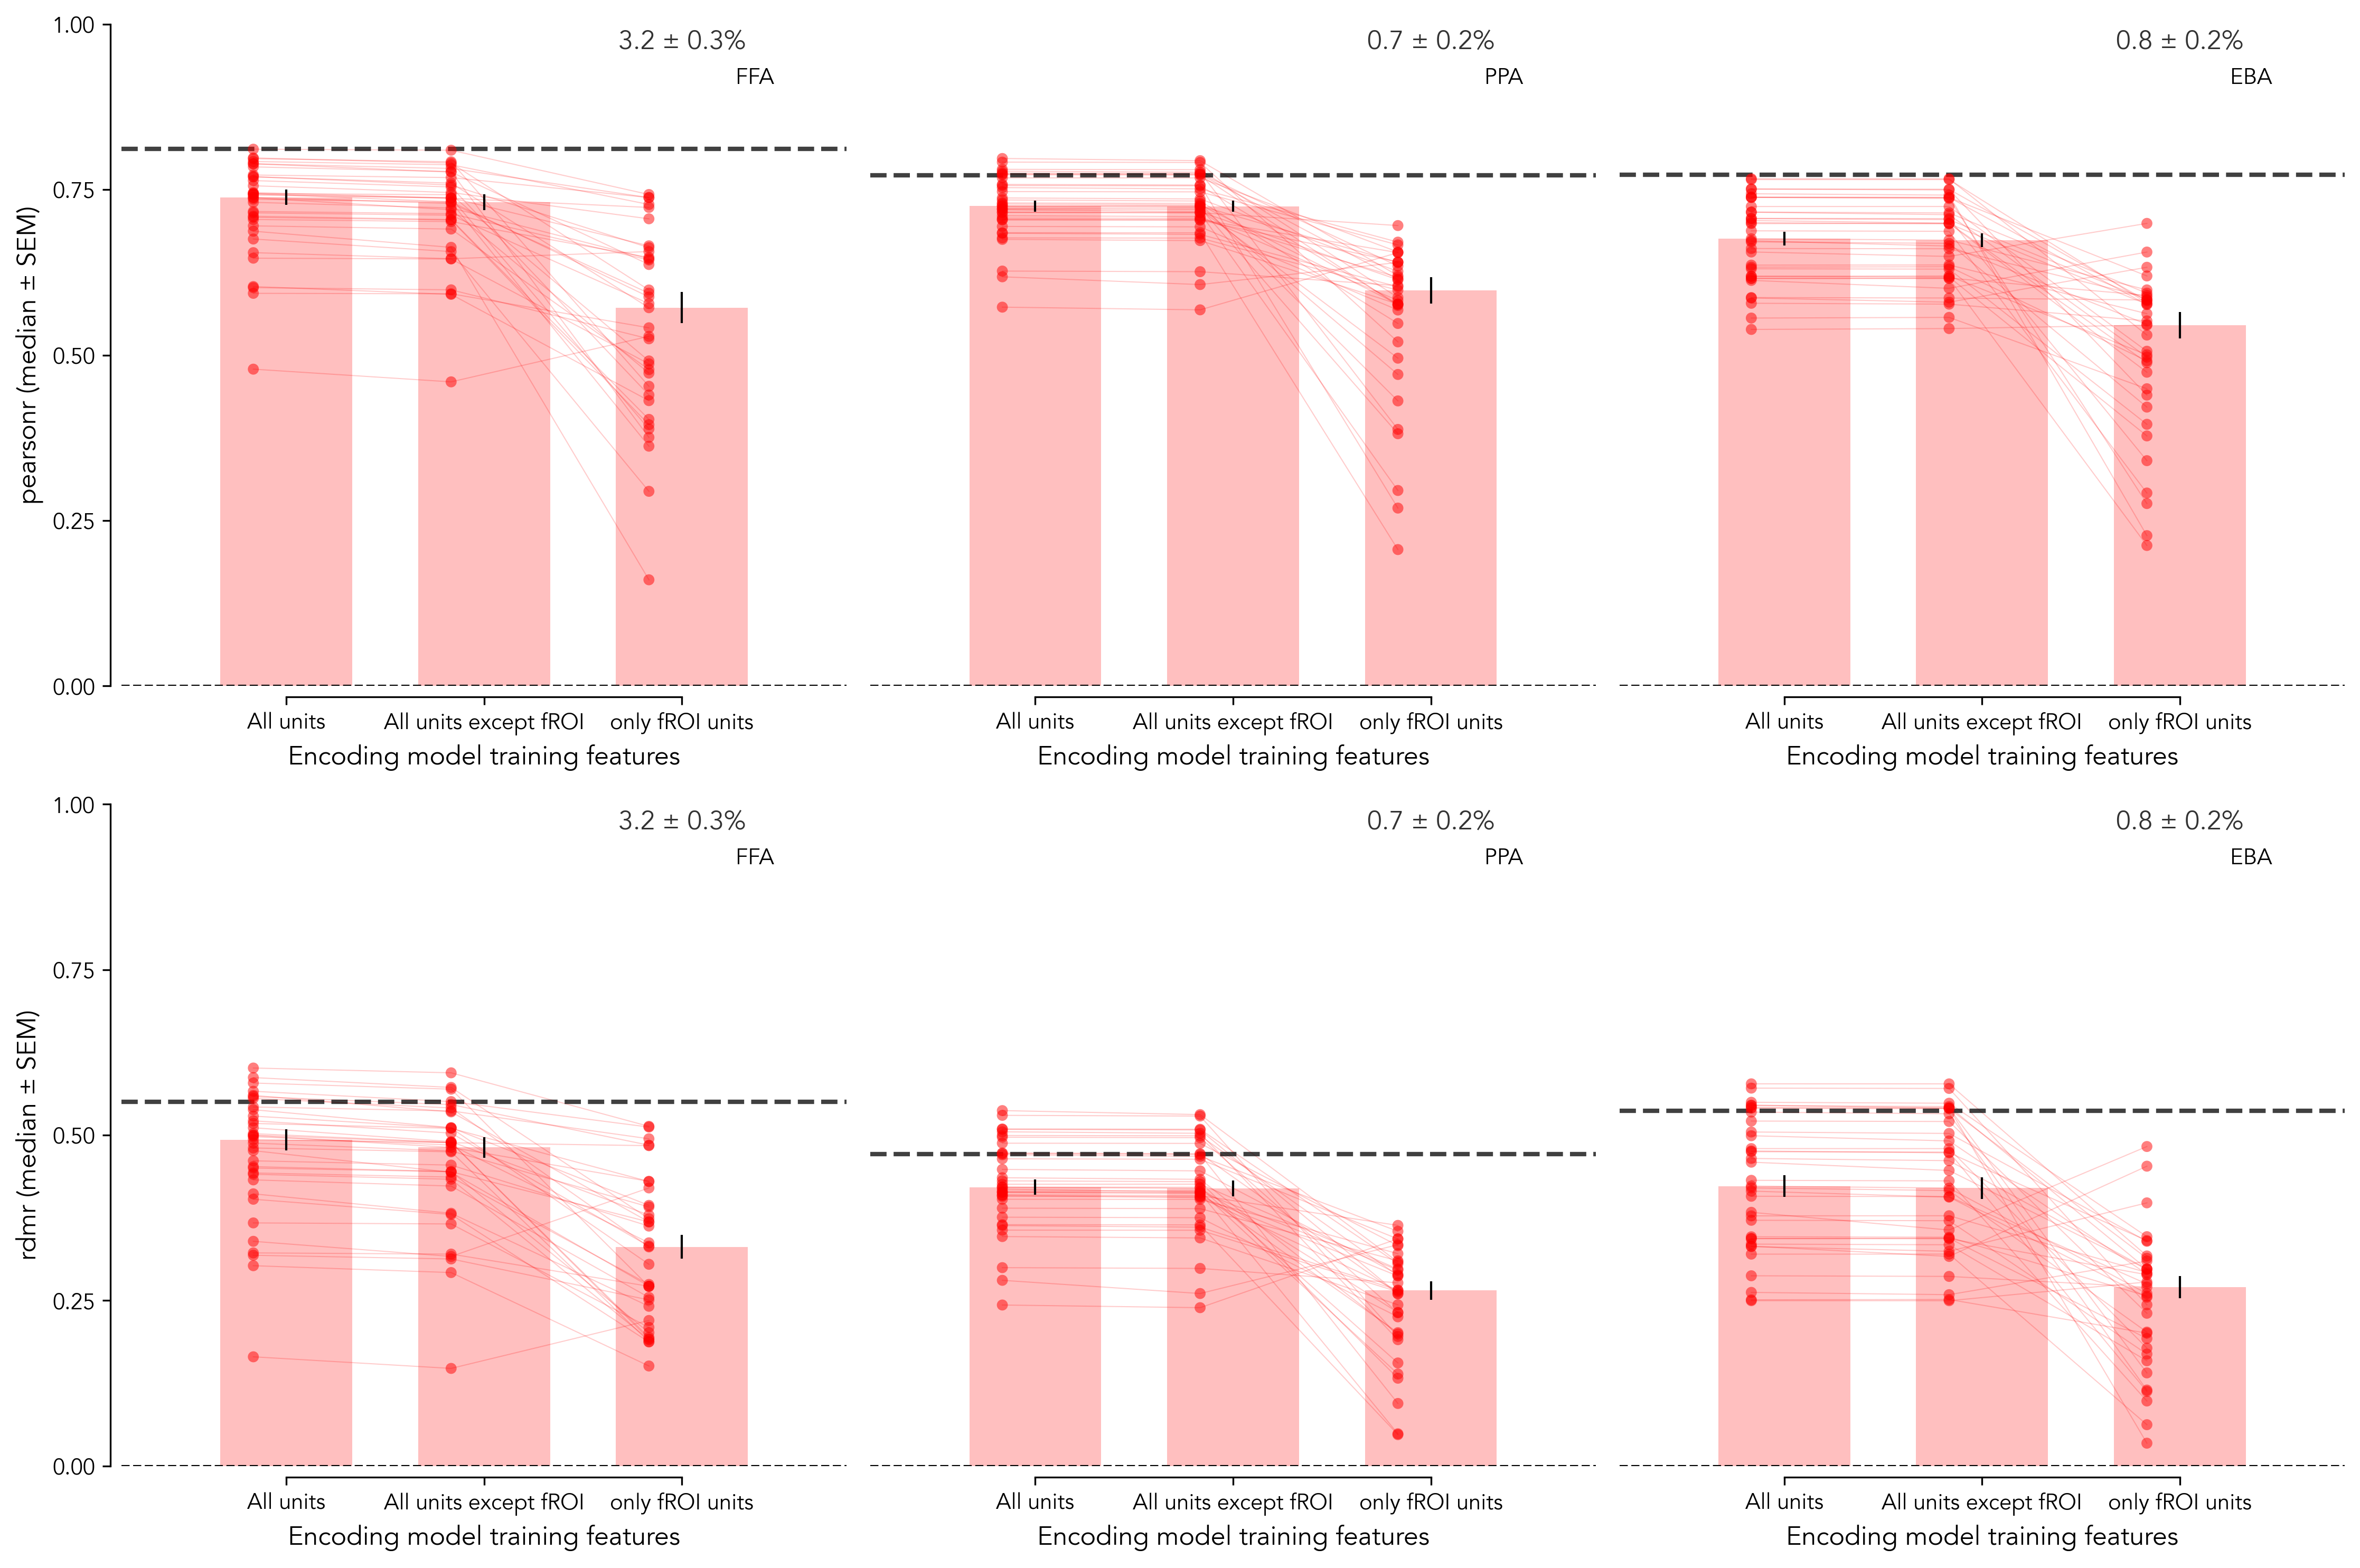

,froi,metric,layer_norm_pvalue,froi_norm_pvalue,lesion_norm_pvalue,layer_lesion_tvalue,layer_lesion_pvalue,layer_froi_tvalue,layer_froi_pvalue,layer_lesion_wstat,layer_lesion_pvalue_w,layer_froi_wstat,layer_froi_pvalue_w
0,FFA,raw_pearsonr,0.000928,0.156163,0.000883,8.325304,1.020031e-09,7.513631,1.009694e-08,0.0,5.820766e-11,5.0,5.820766e-10
1,FFA,raw_rdmr,0.008910,0.074231,0.007283,9.756830,2.182899e-11,8.937971,1.905756e-10,0.0,5.820766e-11,14.0,6.402843e-09
2,PPA,raw_pearsonr,0.028364,0.000043,0.014339,3.575774,1.071629e-03,7.282786,1.964002e-08,19.0,1.786975e-08,11.0,3.201421e-09
3,PPA,raw_rdmr,0.207176,0.016968,0.098129,3.368927,1.889451e-03,9.328540,6.706495e-11,11.0,3.201421e-09,11.0,3.201421e-09
4,EBA,raw_pearsonr,0.171718,0.009189,0.197673,3.373798,1.864653e-03,7.074053,3.600897e-08,101.0,2.429703e-04,20.0,2.159504e-08
5,EBA,raw_rdmr,0.092036,0.621553,0.093221,3.495289,1.338134e-03,6.963401,4.973870e-08,30.0,1.184526e-07,30.0,1.184526e-07


In [ ]:
savefig = True

lesion_csv_path = f'{RESULTS_DIR}/layer_froi_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)

plot_dir = f'{PLOTS_DIR}/fig5/'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7
subjects = [1, 2, 5, 7]
metrics = ['raw_pearsonr', 'raw_rdmr']
layer_lesion_froi_stats_df = []

# Take median across subjects for each model, fmri_froi
# Select values according to t_threshold
results_df = results_df[
    (results_df['model_tthreshold'] == t_threshold) &
    (results_df['fmri_tthreshold'] == t_threshold)
]
results_df_froi_sbjmedian = results_df.groupby(
    ['model', 'fmri_froi']
).agg({
    'layer_raw_pearsonr': 'median',
    'layer_raw_rdmr': 'median',
	'froi_raw_pearsonr': 'median',
    'froi_raw_rdmr': 'median',
    'lesion_raw_pearsonr': 'median',
    'lesion_raw_rdmr': 'median',
    'percent_units_lesioned': 'median',
    'fmri_splithalf_pearsonr': 'median',
    'fmri_splithalf_rdmr': 'median',
}).reset_index()

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_froi_sbjmedian[results_df_froi_sbjmedian['fmri_froi'] == froi]
    # Get fmri_splithalf_pearsonr, fmri_splithalf_rdmr from the first row
    ceiling = {
        'raw_pearsonr': results_df_froi['fmri_splithalf_pearsonr'].values[0],
        'raw_rdmr': results_df_froi['fmri_splithalf_rdmr'].values[0],
    }
    for midx, metric in enumerate(metrics):
        # Plot ceiling as a horizontal line
        axs[midx, fidx].axhline(y=ceiling[metric], color='k', linestyle='--', alpha=0.75, linewidth=2)

        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        froi_pts = np.array(results_df_froi[f'froi_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        x_layer = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[1]) - x_offset
        x_froi = (np.ones(len(froi_pts)) * x[2]) - x_offset
        axs[midx, fidx].scatter(
            x_layer, layer_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx, fidx].plot(
                [x_layer[i], x_lesion[i], x_froi[i]], 
                [layer_pts[i], lesion_pts[i], froi_pts[i]], 
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(layer_pts), np.median(lesion_pts), np.median(froi_pts)]
        sems = [
            layer_pts.std() / np.sqrt(len(layer_pts)),
            lesion_pts.std() / np.sqrt(len(lesion_pts)),
            froi_pts.std() / np.sqrt(len(froi_pts)),
        ]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Stats
        # test normality
        layer_norm_pvalue = scipy.stats.shapiro(layer_pts)[1]
        froi_norm_pvalue = scipy.stats.shapiro(froi_pts)[1]
        lesion_norm_pvalue = scipy.stats.shapiro(lesion_pts)[1]
        # Conduct Welch's t-test
        layer_lesion_tvalue, layer_lesion_pvalue = scipy.stats.ttest_rel(
            layer_pts, lesion_pts, alternative='two-sided'
        )
        layer_froi_tvalue, layer_froi_pvalue = scipy.stats.ttest_rel(
            layer_pts, froi_pts, alternative='two-sided'
        )
        # Conduct Wilcoxon signed-rank test
        layer_lesion_wstat, layer_lesion_pvalue_w = scipy.stats.wilcoxon(
            layer_pts, lesion_pts, alternative='two-sided'
        )
        layer_froi_wstat, layer_froi_pvalue_w = scipy.stats.wilcoxon(
            layer_pts, froi_pts, alternative='two-sided'
        )
        # Store stats
        layer_lesion_stats = {
            'froi': froi,
            'metric': metric,
            'layer_norm_pvalue': layer_norm_pvalue,
            'froi_norm_pvalue': froi_norm_pvalue,
            'lesion_norm_pvalue': lesion_norm_pvalue,
            'layer_lesion_tvalue': layer_lesion_tvalue,
            'layer_lesion_pvalue': layer_lesion_pvalue,
            'layer_froi_tvalue': layer_froi_tvalue,
            'layer_froi_pvalue': layer_froi_pvalue,
            'layer_lesion_wstat': layer_lesion_wstat,
            'layer_lesion_pvalue_w': layer_lesion_pvalue_w,
            'layer_froi_wstat': layer_froi_wstat,
            'layer_froi_pvalue_w': layer_froi_pvalue_w,
        }
        layer_lesion_froi_stats_df.append(layer_lesion_stats)

        # Get % units lesioned for this froi
        percent_lesioned_list = results_df_froi['percent_units_lesioned']
        pl_mean = np.mean(percent_lesioned_list)
        pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        axs[midx, fidx].text(
                x[-1], 0.95,
                f"{pl_mean:.1f} ± {pl_sem:.1f}%",
                horizontalalignment='center', verticalalignment='bottom',
                fontsize=12, color='black', alpha=0.8
            )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All units', 'All units except fROI', 'only fROI units'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'{metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model training features', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/fig5_allunitsEM_froilesionedEM_froionlyEM.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

layer_lesion_froi_stats_df = pd.DataFrame(layer_lesion_froi_stats_df)
display(layer_lesion_froi_stats_df)

## Individual fROIs (L1-positive)

In [ ]:
# TODO

# Across t-values (fixed alpha)

In [2]:
lesion_csv_path = f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha.csv'
lesion_csv = pd.read_csv(lesion_csv_path)
# lesion_csvs = [f'{RESULTS_DIR}/nsd515_lesion_ems_fixedalpha_v{i}.csv' for i in range(1, 8)]

# if not os.path.exists(lesion_csv_path):
#     lesion_csv = pd.concat([pd.read_csv(lesion_csv) for lesion_csv in lesion_csvs])
#     lesion_csv.to_csv(lesion_csv_path, index=False)
# else:
#     lesion_csv = pd.read_csv(lesion_csv_path)
# print("Number of rows for each fROI:")
# print(lesion_csv['fmri_froi'].value_counts())

In [10]:
savefig = True

fmri_tthreshold = 7

plot_dir = f'{PLOTS_DIR}/fig5/across_tvals'
os.makedirs(plot_dir, exist_ok=True)

results_df = lesion_csv.copy()
subjectsubject_correlations_csv = pd.read_csv(SUBJECTSUBJECT_CORRELATIONS_CSV_PATH)
subjects = results_df['subject'].unique().tolist()

frois = ['FFA', 'PPA', 'EBA']
ordered_tthresholds = [-1, 11, 9, 7, 5, 3]
xticks_dict = {
    -1: 'Intact',
    11: '11',
    9: '9',
    7: '7',
    5: '5',
    3: '3'
}
metrics = ['normed_pearsonr', 'normed_rdmr']
plot_ceiling = False

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6, 0.9, 1.2, 1.5]
fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

for midx, metric in enumerate(metrics):
    for fidx, froi in enumerate(frois):
        print(metric, froi)
        # For specific froi & fmri_tthreshold, get results_df
        results_df_froi = results_df[
            (results_df['model_froi'] == froi) &
            (results_df['fmri_froi'] == froi) &
            (results_df['fmri_tthreshold'] == fmri_tthreshold)
        ]
        # Take median across subjects for each model, model_threshold
        results_df_froi_sbjmedian = results_df_froi.groupby(
            ['model', 'model_tthreshold']
        ).agg({
            'raw_pearsonr': 'median',
            'normed_pearsonr': 'median',
            'raw_rdmr': 'median',
            'normed_rdmr': 'median',
            'n_units_layer': 'mean',
            'n_units_lesioned': 'mean',
            'percent_units_lesioned': 'mean',
        }).reset_index()

        if plot_ceiling:
            ceiling_values = []
            for subject1_idx in range(len(subjects)):
                for subject2_idx in range(subject1_idx, len(subjects)):
                    subject1 = subjects[subject1_idx]
                    subject2 = subjects[subject2_idx]
                    if subject1 == subject2:
                        continue
                    subjectsubject_froi = subjectsubject_correlations_csv[
                        (subjectsubject_correlations_csv['fmri_froi'] == froi) &
                        (subjectsubject_correlations_csv['subject1'] == subject1) &
                        (subjectsubject_correlations_csv['subject2'] == subject2) & 
                        (subjectsubject_correlations_csv['fmri_tthreshold'] == 7)
                    ]
                    ceiling_metric_ = 'pearsonr' if metric == 'raw_pearsonr' else metric
                    ceiling_values += list(subjectsubject_froi[ceiling_metric_])
                    # print(f'Subject {subject1} vs Subject {subject2}: {subjectsubject_froi[ceiling_metric]}')
            ceiling_values = np.array(ceiling_values).flatten()
            # print(f'Ceiling values: {ceiling_values}')
            ceiling_median = np.median(ceiling_values)
            ceiling_sem = np.std(ceiling_values) / np.sqrt(len(ceiling_values))

            # Plot horizontal line at median of ceiling values
            plt.axhline(y=ceiling_median, color='royalblue', linestyle='-', alpha=0.8, linewidth=1, zorder=1)

            # Fill area around the line for SEM
            plt.fill_between(
                [x[0]-0.5, x[1]+0.5],  # Extend across full x range
                ceiling_median - ceiling_sem,
                ceiling_median + ceiling_sem,
                color='royalblue', alpha=0.2, zorder=0, edgecolor='none'
            )

        
        # model_tthresholds = results_df_froi_sbjmedian['model_tthreshold'].unique()
        model_tthresholds = ordered_tthresholds
        assert set(model_tthresholds) == set(ordered_tthresholds), \
            f"Model tthresholds {model_tthresholds} are same as ordered tthresholds {ordered_tthresholds}"
        n_model_tthresholds = len(model_tthresholds)

        # percent_lesioned_means = []
        # percent_lesioned_sems = []

        xticklabels = []

        for tidx, model_tthreshold in enumerate(model_tthresholds):
            tthreshold_results = results_df_froi_sbjmedian[
                (results_df_froi_sbjmedian['model_tthreshold'] == model_tthreshold)
            ]
            y_pts = tthreshold_results[metric].values
            percent_lesioneds = tthreshold_results['percent_units_lesioned'].values
            pl_mean = np.mean(percent_lesioneds)
            pl_sem = np.std(percent_lesioneds) / np.sqrt(len(percent_lesioneds))
            # percent_lesioned_means.append(np.mean(percent_lesioneds))
            # percent_lesioned_sems.append(np.std(percent_lesioneds) / np.sqrt(len(percent_lesioneds)))
            # Add text on top of each x point mentioning the percent lesioned mean +- sem
            # axs[midx, fidx].text(
            #     x[tidx] + x_offset, 0.95,
            #     f"{pl_mean:.1f} ± {pl_sem:.1f}%",
            #     horizontalalignment='center', verticalalignment='bottom',
            #     fontsize=8, color='black', alpha=0.8
            # )
            # instead of text, make it x tick labels
            if model_tthreshold == -1:
                xticklabels.append('0%\n(Intact)')
            else:
                xticklabels.append(f"{pl_mean:.1f}%\n(t > {model_tthreshold})")
        
            x_froi = (np.ones(len(y_pts)) * x[tidx]) - x_offset
            axs[midx, fidx].scatter(
                x_froi, y_pts, color='red', alpha=alpha, zorder=2,
                edgecolors='none', s=markersize
            )
            # connect points with a line
            # for i in range(len(froi_pts)):
            #     axs[midx, fidx].plot([x_froi[i], x_lesion[i]], [froi_pts[i], lesion_pts[i]], color='red', alpha=0.2, linewidth=0.5, zorder=1)

            # Bar plot with median and SEM
            bar_width = 0.2 #0.4
            median = np.median(y_pts)
            sem = y_pts.std() / np.sqrt(len(y_pts))

            axs[midx, fidx].bar(x[tidx], median, yerr=sem, width=bar_width, color='red', alpha=0.25, capsize=0, error_kw={'linewidth': 1})
            # # Conduct Welch's t-test
            # t_value, p_value = scipy.stats.ttest_ind(froi_pts, lesion_pts, equal_var=False)
            # # axs[midx, fidx].text(0.95, 0.89,
            # #          f"t-value: {t_value:.2f}\np-value: {p_value:.2e}",
            # #          horizontalalignment='right', verticalalignment='bottom',
            # #          transform=axs[midx, fidx].transAxes)
            # print(f"t-value: {t_value:.2f}\np-value: {p_value:.2e}")
        axs[midx, fidx].text(0.95, 0.89,
                    froi,
                    horizontalalignment='right', verticalalignment='bottom',
                    transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        axs[midx, fidx].set_ylim(0, 1)
        # axs[midx, fidx].tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        # xticklabels = [xticks_dict[t] for t in model_tthresholds]
        axs[midx, fidx].set_xticks(x, xticklabels, fontsize=10)
        # axs[midx, fidx].xticks(x, model_tthresholds)
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # axs[midx, fidx].tick_params(axis='x', labelbottom=False)
        # axs[midx, fidx].xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')
        # plt.title(f'{froi} fROI, mapper: Ridge', fontsize=14, pad=10)

        # Stats
        # Run an ANOVA on normed_pearsonr across model_tthresholds to see if there is a significant difference
        anova_results = scipy.stats.f_oneway(
            *[results_df_froi_sbjmedian[results_df_froi_sbjmedian['model_tthreshold'] == t][metric].values for t in model_tthresholds]
        )
        print(f"ANOVA results for {froi}, metric {metric}: F-value = {anova_results.statistic:.3f}, p-value = {anova_results.pvalue:.3e}")
        # Print the median and SEM for each model_tthreshold
        # for model_tthreshold in model_tthresholds:
        #     tthreshold_results = results_df_froi_sbjmedian[
        #         (results_df_froi_sbjmedian['model_tthreshold'] == model_tthreshold)
        #     ]
        #     median = tthreshold_results[metric].median()
        #     sem = tthreshold_results[metric].std() / np.sqrt(len(tthreshold_results))
            # print(f"Model tthreshold {model_tthreshold}: median = {median:.3f}, SEM = {sem:.3f}")
        # Run t-tests between neighboring pairs of ordered_tthresholds
        for i in range(len(ordered_tthresholds) - 1):
            t1 = ordered_tthresholds[0]
            t2 = ordered_tthresholds[i + 1]
            t1_results = results_df_froi_sbjmedian[results_df_froi_sbjmedian['model_tthreshold'] == t1][metric].values
            t2_results = results_df_froi_sbjmedian[results_df_froi_sbjmedian['model_tthreshold'] == t2][metric].values
            t_stat, p_val = scipy.stats.ttest_ind(t1_results, t2_results, equal_var=False)
            print(f"T-test between {t1} and {t2}: t-statistic = {t_stat:.3f}, p-value = {p_val:.3e}")

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/lesioned_tvals_ridge_individualfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()

normed_pearsonr FFA
ANOVA results for FFA, metric normed_pearsonr: F-value = 0.129, p-value = 9.858e-01
T-test between -1 and 11: t-statistic = 0.331, p-value = 7.416e-01
T-test between -1 and 9: t-statistic = 0.421, p-value = 6.747e-01
T-test between -1 and 7: t-statistic = 0.518, p-value = 6.058e-01
T-test between -1 and 5: t-statistic = 0.615, p-value = 5.403e-01
T-test between -1 and 3: t-statistic = 0.726, p-value = 4.700e-01
normed_pearsonr PPA
ANOVA results for PPA, metric normed_pearsonr: F-value = 0.008, p-value = 1.000e+00
T-test between -1 and 11: t-statistic = 0.055, p-value = 9.561e-01
T-test between -1 and 9: t-statistic = 0.066, p-value = 9.477e-01
T-test between -1 and 7: t-statistic = 0.094, p-value = 9.251e-01
T-test between -1 and 5: t-statistic = 0.125, p-value = 9.011e-01
T-test between -1 and 3: t-statistic = 0.189, p-value = 8.507e-01
normed_pearsonr EBA
ANOVA results for EBA, metric normed_pearsonr: F-value = 0.009, p-value = 1.000e+00
T-test between -1 and 11: 

# (Pre-VSS/during-VSS generated) All units vs. froi only vs froi lesioned

Model alexnetipclref01 has froi_pts >= layer_pts and lesion_pts for FFA, metric normed_pearsonr
Model resnet50ecoset has froi_pts >= layer_pts and lesion_pts for FFA, metric normed_pearsonr
froi: FFA, metric: normed_pearsonr, layer median: 0.840, froi median: 0.740, lesion median: 0.830
froi: FFA, metric: normed_pearsonr: t-value: 7.56, p-value: 1.32e-08
froi: FFA, metric: normed_pearsonr: U-statistic: 0.00, p-value (Wilcoxon): 2.33e-10

Model alexnetipclref01 has froi_pts >= layer_pts and lesion_pts for FFA, metric normed_rdmr
Model resnet50ecoset has froi_pts >= layer_pts and lesion_pts for FFA, metric normed_rdmr
froi: FFA, metric: normed_rdmr, layer median: 0.700, froi median: 0.567, lesion median: 0.685
froi: FFA, metric: normed_rdmr: t-value: 8.64, p-value: 7.12e-10
froi: FFA, metric: normed_rdmr: U-statistic: 0.00, p-value (Wilcoxon): 2.33e-10

froi: PPA, metric: normed_pearsonr, layer median: 0.835, froi median: 0.761, lesion median: 0.834
froi: PPA, metric: normed_pearsonr: t-

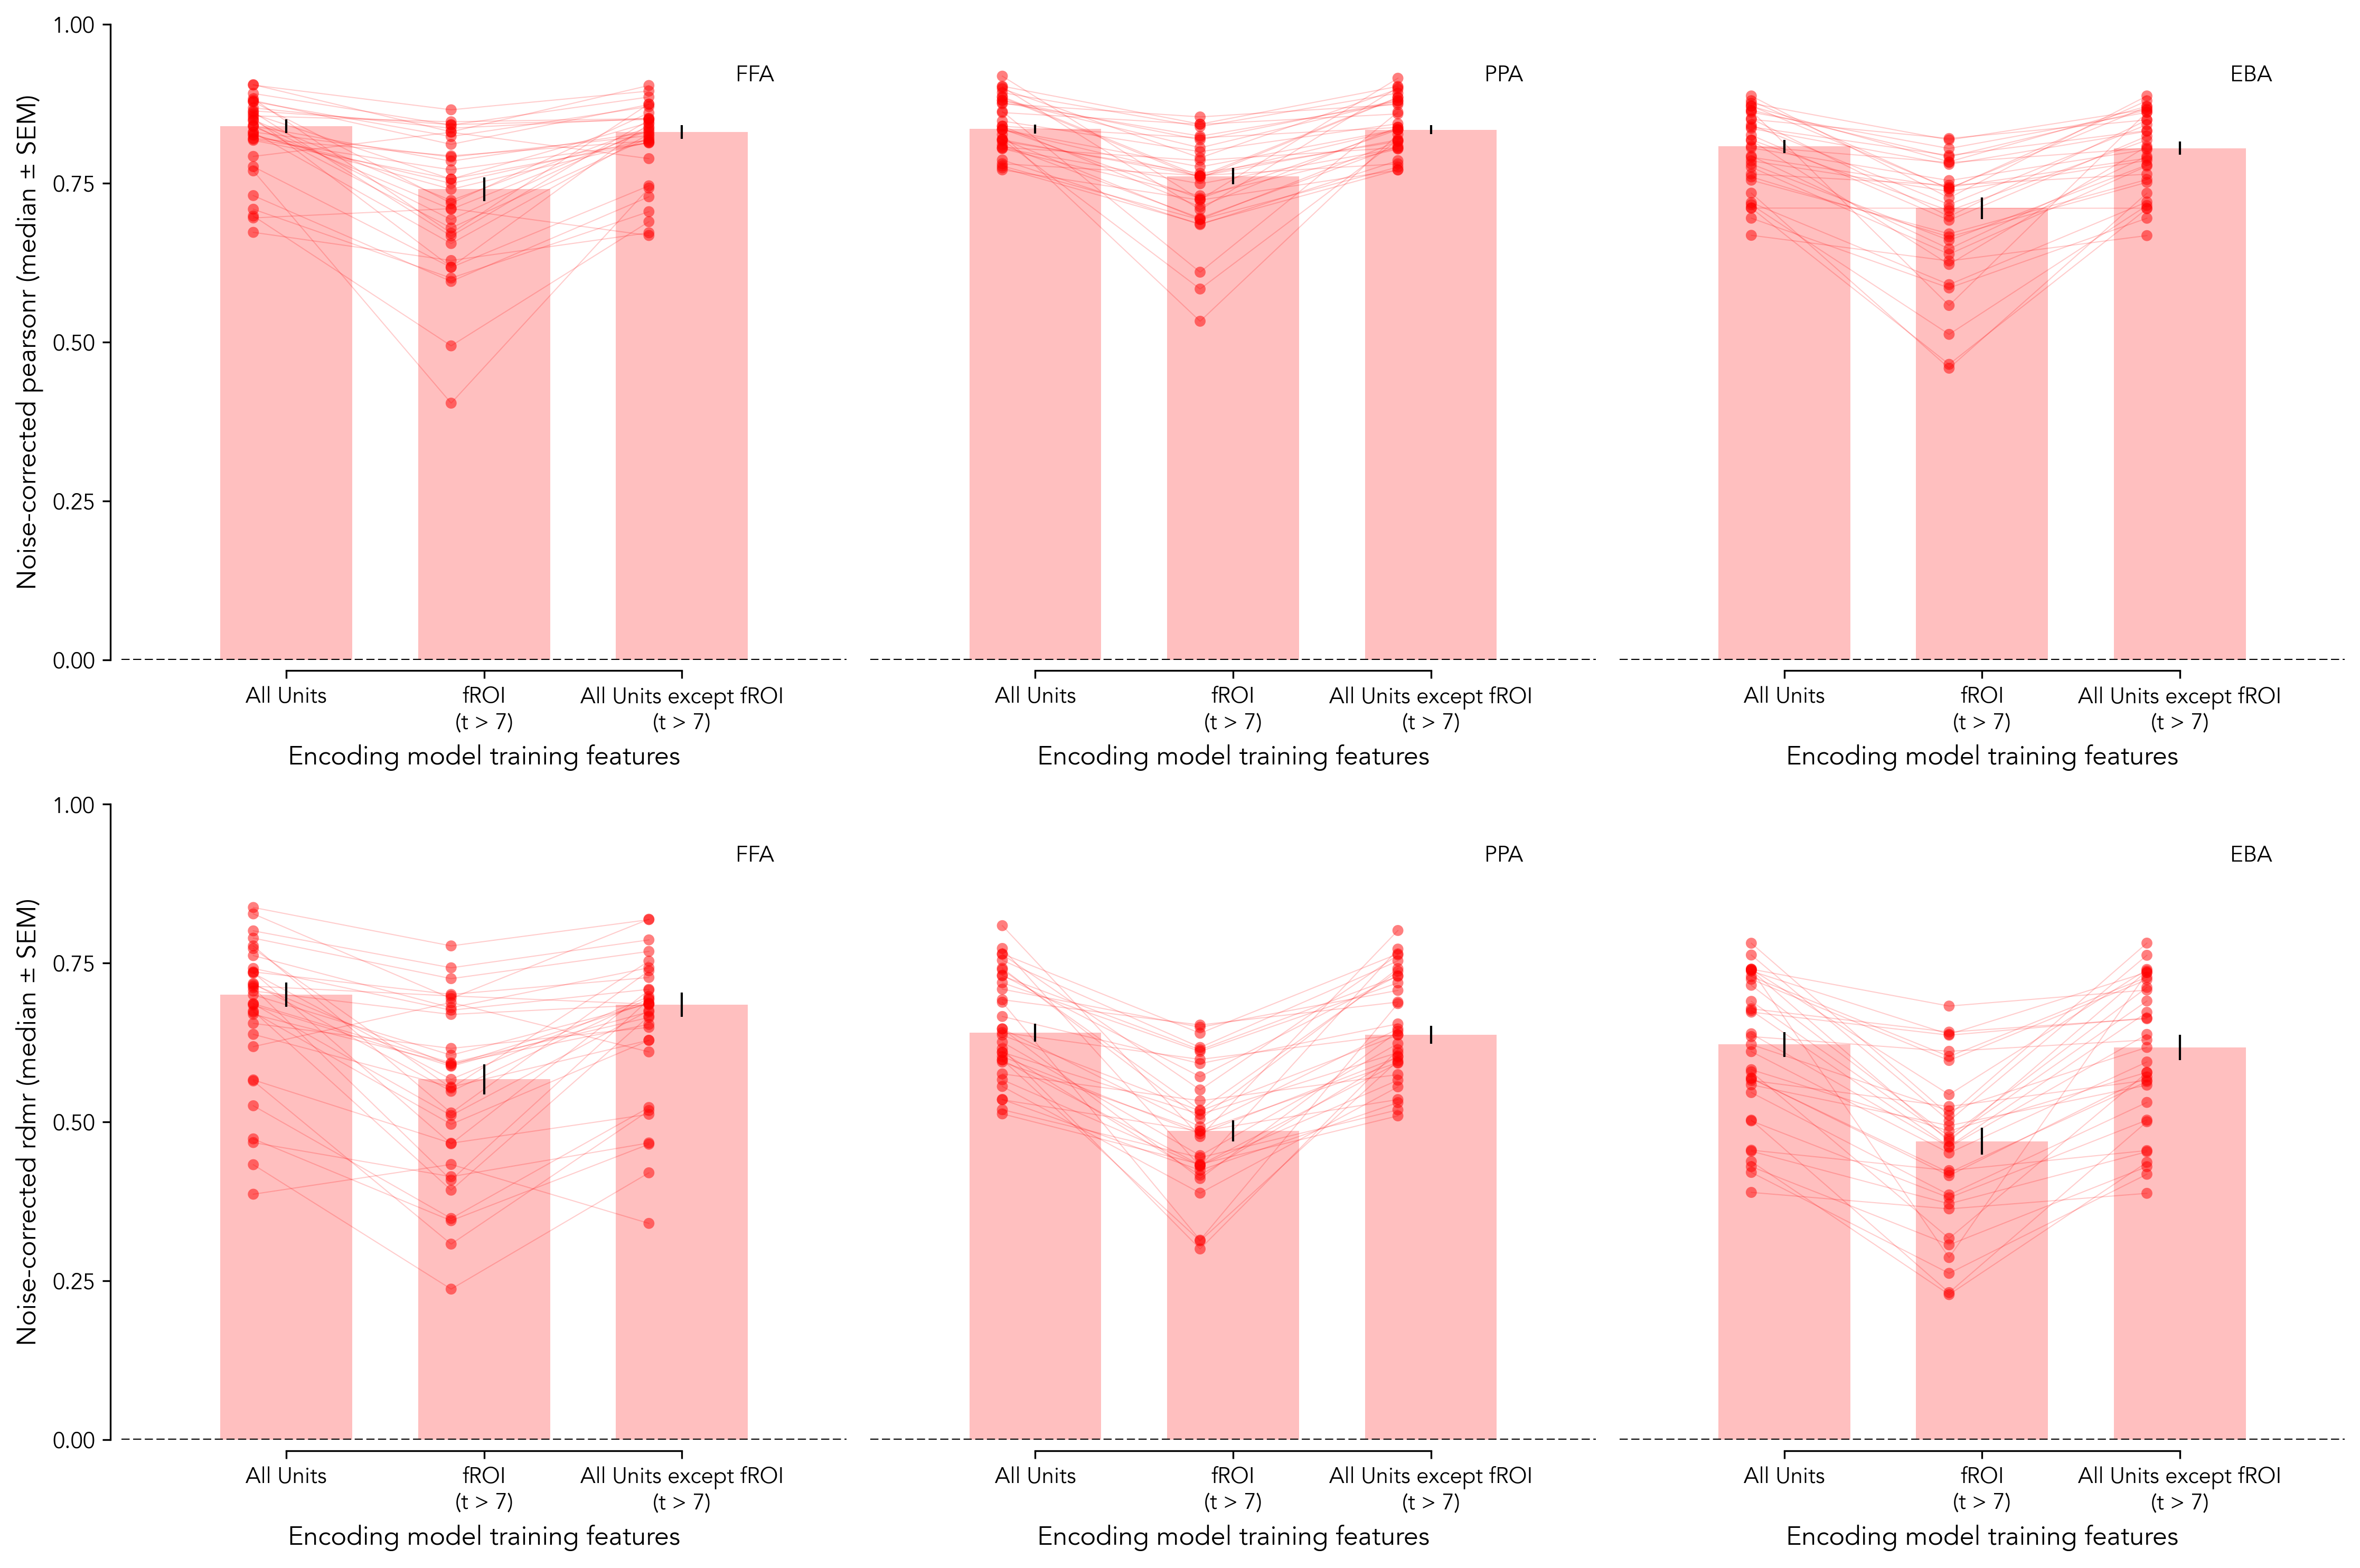

In [2]:
savefig = False

# plot_dir = f'{PLOTS_DIR}/fig5/intact_t7_lesioned'
# os.makedirs(plot_dir, exist_ok=True)

results_dir = f'{RESULTS_DIR}/vss25_lesion_ems'
# csv generate pre-vss, with alpha optimized EMs for
# froi only (t > 7), and
# froi lesioned (t > 0)
prevss_csv_path = f'{results_dir}/nsd515_ridge_lesion.csv'
prevss_csv = pd.read_csv(prevss_csv_path)
prevss_csv = prevss_csv.drop_duplicates(keep='first')
# csv generate during-vss, with alpha optimized EMs for
# all units, and
# froi lesioned (t > 7)
duringvss_csv_path = f'{results_dir}/vss_nsd515_ridge_lesion.csv'
duringvss_csv = pd.read_csv(duringvss_csv_path)

# Group by model, model_froi and fmri_froi, and take median across subjects for the column froi_normed_pearsonr and froi_normed_rdmr
prevss_csv_froi_sbjmedian = prevss_csv.groupby(
    ['model', 'model_froi', 'fmri_froi']
).agg({
    'froi_normed_pearsonr': 'median',
    'froi_normed_rdmr': 'median',
}).reset_index()

# Do the same for duringvss_csv
duringvss_csv_froi_sbjmedian = duringvss_csv.groupby(
    ['model', 'model_froi', 'fmri_froi']
).agg({
    'layer_normed_pearsonr': 'median',
    'layer_normed_rdmr': 'median',
    'lesion_normed_pearsonr': 'median',
    'lesion_normed_rdmr': 'median',
}).reset_index()

# Join both csvs based on model, model_froi, fmri_froi
merged_csv = pd.merge(
    prevss_csv_froi_sbjmedian,
    duringvss_csv_froi_sbjmedian,
    on=['model', 'model_froi', 'fmri_froi'],
)

results_df = merged_csv.copy()
frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7
# subjects = [1, 2, 5, 7]
metrics = ['normed_pearsonr', 'normed_rdmr']

fig, axs = plt.subplots(len(metrics), len(frois), figsize=(5*len(frois), 5*len(metrics)), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df[results_df['fmri_froi'] == froi]
    for midx, metric in enumerate(metrics):
        layer_pts = np.array(results_df_froi[f'layer_{metric}'].tolist())
        froi_pts = np.array(results_df_froi[f'froi_{metric}'].tolist())
        lesion_pts = np.array(results_df_froi[f'lesion_{metric}'].tolist())

        x_layer = (np.ones(len(layer_pts)) * x[0]) - x_offset
        x_froi = (np.ones(len(froi_pts)) * x[1]) - x_offset
        x_lesion = (np.ones(len(lesion_pts)) * x[2]) - x_offset
        axs[midx, fidx].scatter(
            x_layer, layer_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_froi, froi_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        axs[midx, fidx].scatter(
            x_lesion, lesion_pts, color='red', alpha=alpha, zorder=2,
            edgecolors='none', s=markersize
        )
        # connect points with a line
        for i in range(len(froi_pts)):
            axs[midx, fidx].plot(
                [x_layer[i], x_froi[i], x_lesion[i]], [layer_pts[i], froi_pts[i], lesion_pts[i]],
                color='red', alpha=0.2, linewidth=0.5, zorder=1
            )
            if (froi_pts[i] >= layer_pts[i]) and (froi_pts[i] >= lesion_pts[i]):
                # print the model name
                model_name = results_df_froi.iloc[i]['model']
                print(f"Model {model_name} has froi_pts >= layer_pts and lesion_pts for {froi}, metric {metric}")

        # Bar plot with median and SEM
        bar_width = 0.2 #0.4
        medians = [np.median(layer_pts), np.median(froi_pts), np.median(lesion_pts)]
        sems = [
            layer_pts.std() / np.sqrt(len(layer_pts)),
            froi_pts.std() / np.sqrt(len(froi_pts)),
            lesion_pts.std() / np.sqrt(len(lesion_pts))
        ]

        axs[midx, fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
        # Stats
        print(f"froi: {froi}, metric: {metric}, layer median: {np.median(layer_pts):.3f}, froi median: {np.median(froi_pts):.3f}, lesion median: {np.median(lesion_pts):.3f}")
        # Conduct Welch's t-test and mann whitney u test between layer and lesioned points
        t_value, p_value = scipy.stats.ttest_rel(layer_pts, lesion_pts)
        print(f"froi: {froi}, metric: {metric}: t-value: {t_value:.2f}, p-value: {p_value:.2e}")
        # Conduct Wilcoxon U test
        u_stat, p_value_mwu = scipy.stats.wilcoxon(layer_pts, lesion_pts, alternative='two-sided')
        print(f"froi: {froi}, metric: {metric}: U-statistic: {u_stat:.2f}, p-value (Wilcoxon): {p_value_mwu:.2e}")
        print()

        # # Get % units lesioned for this froi
        # # For specific froi & fmri_tthreshold, get results_df
        # lesion_fixedalpha_csv_froi = lesion_fixedalpha_csv[
        #     (lesion_fixedalpha_csv['model_froi'] == froi) &
        #     (lesion_fixedalpha_csv['fmri_froi'] == froi) &
        #     (lesion_fixedalpha_csv['model_tthreshold'] == t_threshold) &
        #     (lesion_fixedalpha_csv['fmri_tthreshold'] == t_threshold)
        # ]
        # # Take median across subjects for each model, model_threshold
        # lesion_fixedalpha_csv_froi_sbjmedian = lesion_fixedalpha_csv_froi.groupby(
        #     ['model', 'model_tthreshold']
        # ).agg({
        #     'percent_units_lesioned': 'mean',
        # }).reset_index()
        # percent_lesioned_list = lesion_fixedalpha_csv_froi_sbjmedian['percent_units_lesioned']
        # pl_mean = np.mean(percent_lesioned_list)
        # pl_sem = percent_lesioned_list.std() / np.sqrt(len(percent_lesioned_list))
        # axs[midx, fidx].text(
        #         x[-1], 0.95,
        #         f"{pl_mean:.1f} ± {pl_sem:.1f}%",
        #         horizontalalignment='center', verticalalignment='bottom',
        #         fontsize=12, color='black', alpha=0.8
        #     )

        # Label fROI
        axs[midx, fidx].text(0.9, 0.9,
                 froi,
                 horizontalalignment='right', verticalalignment='bottom',
                 transform=axs[midx, fidx].transAxes)

        axs[midx, fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

        axs[midx, fidx].spines['top'].set_visible(False)
        axs[midx, fidx].spines['right'].set_visible(False)
        axs[midx, fidx].spines['left'].set_position(('outward', 5))
        axs[midx, fidx].spines['bottom'].set_position(('outward', 5))
        axs[midx, fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
        axs[midx, fidx].spines['left'].set_bounds(0, 1)
        plt.ylim(0, 1)
        # plt.tick_params(axis='y', labelleft=False)
        axs[midx, fidx].spines['bottom'].set_bounds(x[0], x[-1])
        axs[midx, fidx].set_xticks(x, ['All Units', 'fROI\n(t > 7)', 'All Units except fROI\n(t > 7)'])
        axs[midx, fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
        # plt.tick_params(axis='x', labelbottom=False)
        # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
        axs[midx, fidx].set_ylabel(f'Noise-corrected {metric.split("_")[-1]} (median ± SEM)', fontsize=12)
        axs[midx, fidx].set_xlabel(f'Encoding model training features', fontsize=12)

        if froi != 'FFA':
            axs[midx, fidx].spines['left'].set_visible(False)
            # Stop showing y-axis ticks
            axs[midx, fidx].yaxis.set_ticks([])
            axs[midx, fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    raise NotImplementedError("Exploration only")
    plt.savefig(f'{plot_dir}/lesioned_ridge_individualfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()